In [ ]:
# Regularization Hyperparameters

[0.52635049 1.00284361] (150, 2)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


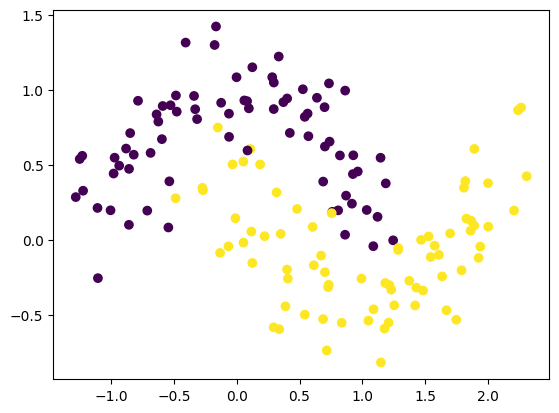

In [ ]:
# Take a toy dataset for binary classification
# Сначала обучим без регулизации, а потом с min_samples_leaf=5

from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier
import numpy as np
import matplotlib.pyplot as plt

X_moons, y_moons = make_moons(n_samples=150, noise=0.2, random_state=42)
# Две вложенные луны
print(X_moons[5], X_moons.shape)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons) # Что за данные, все x1 = [:,0] все x2 = [:,1]
tree_clf1 = DecisionTreeClassifier(random_state=42)
tree_clf2 = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)
tree_clf1.fit(X_moons, y_moons)
tree_clf2.fit(X_moons, y_moons)


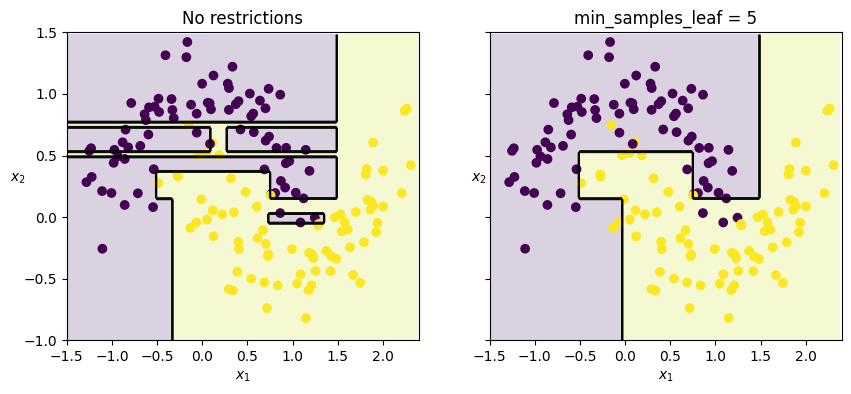

In [ ]:
def draw(clf, X, y, axes):
    x_min, x_max, y_min, y_max = axes
    # Разметить шахматную сетку x y по мин и максам с шагом 0.02 (дает больше клеток)
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    # Склеить их и предсказать получить классы [0,1]
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.2) # Желтый и фиолетовый фон; 0 жетлый, 1 фиолет
    plt.contour(xx, yy, Z, colors="k", linewidths=0.5) # Границы решений
    plt.scatter(X[:, 0], X[:, 1], c=y, marker="o") # точки
    plt.axis(axes)  # Задать диапазон осей
    plt.xlabel(r"$x_1$"); plt.ylabel(r"$x_2$", rotation=0)

# tree_clf1
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 4), sharey=True)
plt.sca(ax1)
draw(tree_clf1, X_moons, y_moons, axes=[-1.5, 2.4, -1, 1.5])
plt.title("No restrictions")

# tree_clf2
plt.sca(ax2)
draw(tree_clf2, X_moons, y_moons, axes=[-1.5, 2.4, -1, 1.5])
plt.title("min_samples_leaf = 5")
plt.sca(ax2)

# Точки данные
# Цвет что предсказывает дерево в этой точке
# Черные линии границы решения

# Левое дерево (без ограничений):
# - тонкие полки и «карманы» — области, созданные ради 1–3 конкретных точек;
# - оно идеально попало в обучающие данные — и именно это плохо: такие полки выучены по шуму (переобучение).

# Правое (min_samples_leaf=5):
# - крупные, ровные области;
# - ни одна точка не может создать лист меньше 5 примеров → мелкие карманы невозможны;
# - несколько точек попало «не в свой» цвет — это нормальная плата за обобщение.


In [2]:
# Evaluating both trees on a test set

X_moons_test, y_moons_test = make_moons(n_samples=1000, noise=0.2, random_state=43)

print("tree_clf1:",tree_clf1.score(X_moons_test, y_moons_test))
print("tree_clf2", tree_clf2.score(X_moons_test,  y_moons_test))

tree_clf1: 0.898
tree_clf2 0.92


In [ ]:
# Regression